In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from io import BytesIO
from urllib.parse import unquote_plus
import requests
import matplotlib.pyplot as plt
import json, os

In [2]:
os.environ["CUDA_VISIBLE_DEVICES"] = "2"

BASE_DIR         = "/home/23dcs510/Smart-Recommendation-System/brain/"
MODEL_PATH       = BASE_DIR + "neural_interaction_model.pth"
USER_EMB_PATH    = BASE_DIR + "user_embeddings.npy"
USER_IDS_PATH    = BASE_DIR + "user_ids.npy"
POI_EMB_PATH     = BASE_DIR + "poi_embeddings_262.npy"
POI_IDS_PATH     = BASE_DIR + "poi_ids_262.npy"
MEMBERSHIP_PATH  = BASE_DIR + "poi_fuzzy_memberships.npy"
CLUSTER_IDS_PATH = BASE_DIR + "poi_cluster_ids.npy"
LABELS_PATH      = BASE_DIR + "poi_aesthetic_labels.csv"
FILTERED_POI     = BASE_DIR + "filtered_poi_ids.npy"
FILTERED_PID     = BASE_DIR + "filtered_photo_ids.npy"
FILTERED_VIS     = BASE_DIR + "filtered_visual_embeddings.npy"
CSV_PATH         = BASE_DIR + "usa_europe_geotagged.csv"

TOP_K            = 5
CANDIDATE_POOL   = 1000
BATCH_SIZE       = 4096

CLUSTER_NAMES = {
    0: "Live Events & Recreation",
    1: "Urban & Street Architecture",
    2: "Historic & Rural Heritage",
    3: "Scenic Nature & Waterscapes",
    4: "Nightlife & Social Scenes",
    5: "Green Nature & Wildlife"
}

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

Device: cuda


In [3]:
class NeuralInteractionLayer(nn.Module):
    def __init__(self, user_dim=262, poi_dim=262):
        super().__init__()
        self.user_tower = nn.Sequential(
            nn.Linear(user_dim, 128), nn.BatchNorm1d(128), nn.GELU(), nn.Dropout(0.2)
        )
        self.poi_tower = nn.Sequential(
            nn.Linear(poi_dim, 128), nn.BatchNorm1d(128), nn.GELU(), nn.Dropout(0.2)
        )
        self.interaction = nn.Sequential(
            nn.Linear(128*3, 256), nn.BatchNorm1d(256), nn.GELU(), nn.Dropout(0.3),
            nn.Linear(256, 128),  nn.BatchNorm1d(128), nn.GELU(), nn.Dropout(0.2),
            nn.Linear(128, 64),   nn.GELU(),
            nn.Linear(64, 1),     nn.Sigmoid()
        )
    def forward(self, u, p):
        u  = self.user_tower(u)
        p  = self.poi_tower(p)
        ip = u * p
        return self.interaction(torch.cat([u, p, ip], dim=1)).squeeze(-1)

# Load model
model = NeuralInteractionLayer().to(DEVICE)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model.eval()

# Load embeddings
user_embeddings  = np.load(USER_EMB_PATH).astype(np.float32)
user_ids         = np.load(USER_IDS_PATH, allow_pickle=True)
poi_embeddings   = np.load(POI_EMB_PATH).astype(np.float32)
poi_ids          = np.load(POI_IDS_PATH)
memberships      = np.load(MEMBERSHIP_PATH).astype(np.float32)
unique_pois      = np.load(CLUSTER_IDS_PATH)
filtered_pois    = np.load(FILTERED_POI)
filtered_pids    = np.load(FILTERED_PID)
filtered_vis     = np.load(FILTERED_VIS).astype(np.float32)

# Load CSV
df               = pd.read_csv(CSV_PATH)
df['photoid']    = df['photoid'].astype(int)
df['uid']        = df['uid'].astype(str)
df_indexed       = df.set_index('photoid')
pid_to_uid       = df.set_index('photoid')['uid'].to_dict()

# Load labels
poi_labels_df    = pd.read_csv(LABELS_PATH)
poi_label_dict   = poi_labels_df.set_index('poi_id')['primary_label'].to_dict()
poi_cluster_dict = poi_labels_df.set_index('poi_id')['primary_cluster'].to_dict()

# Lookup dicts
user_id_to_idx   = {uid: idx for idx, uid in enumerate(user_ids)}
poi_id_to_idx    = {poi: idx for idx, poi in enumerate(poi_ids)}
poi_mem_dict     = {poi: memberships[idx] for idx, poi in enumerate(unique_pois)}

# POI → photo lookup
poi_to_pids = {}
for i, pid in enumerate(filtered_pids):
    poi_to_pids.setdefault(filtered_pois[i], []).append(pid)

poi_emb_tensor = torch.tensor(poi_embeddings, dtype=torch.float32)

print("✓ All assets loaded.")
print(f"  Users : {len(user_ids):,}")
print(f"  POIs  : {len(poi_ids):,}")

✓ All assets loaded.
  Users : 27,071
  POIs  : 169,845


In [4]:
def fetch_image(url, timeout=5):
    try:
        r = requests.get(url, timeout=timeout)
        return Image.open(BytesIO(r.content)).convert('RGB')
    except:
        return None

def get_poi_image(poi_id):
    for pid in poi_to_pids.get(poi_id, [])[:10]:
        if int(pid) not in df_indexed.index: continue
        url = unquote_plus(str(df_indexed.loc[int(pid)]['downloadurl']))
        img = fetch_image(url)
        if img: return img
    return None

def get_user_images(uid, n=5):
    images, pids_used = [], []
    for pid in filtered_pids:
        if pid_to_uid.get(int(pid)) != uid: continue
        if int(pid) not in df_indexed.index: continue
        url = unquote_plus(str(df_indexed.loc[int(pid)]['downloadurl']))
        img = fetch_image(url)
        if img:
            images.append(img)
            pids_used.append(pid)
        if len(images) == n: break
    return images

def recommend_for_user(uid, top_k=TOP_K):
    """
    Full AuraPath inference pipeline for a given user ID.
    Returns ranked list of (poi_id, score, label, cluster_name)
    """
    u_idx    = user_id_to_idx.get(uid, None)
    if u_idx is None:
        print(f"User {uid} not found.")
        return []

    user_emb = user_embeddings[u_idx]

    # Step 1: Aesthetic candidate retrieval
    user_mem      = user_emb[256:]
    poi_mems      = np.array([poi_mem_dict.get(p, np.zeros(6)) for p in poi_ids])
    aes_scores    = poi_mems @ user_mem
    candidate_idx = np.argsort(aes_scores)[::-1][:CANDIDATE_POOL]

    # Step 2: Neural interaction scoring
    cand_embs  = torch.tensor(poi_embeddings[candidate_idx], dtype=torch.float32)
    u_tensor   = torch.tensor(user_emb, dtype=torch.float32).unsqueeze(0)
    scores     = []

    with torch.no_grad():
        for i in range(0, len(candidate_idx), BATCH_SIZE):
            bp = cand_embs[i:i+BATCH_SIZE].to(DEVICE)
            bu = u_tensor.expand(len(bp), -1).to(DEVICE)
            scores.append(model(bu, bp).cpu().numpy())
    scores = np.concatenate(scores)

    # Step 3: Rank and return top-K
    top_local  = np.argsort(scores)[::-1][:top_k]
    top_pois   = poi_ids[candidate_idx[top_local]]
    top_scores = scores[top_local]

    return [
        {
            "poi_id"      : int(p),
            "score"       : round(float(s), 4),
            "label"       : poi_label_dict.get(p, "Unknown"),
            "cluster"     : CLUSTER_NAMES.get(poi_cluster_dict.get(p, -1), "Unknown"),
            "cluster_id"  : int(poi_cluster_dict.get(p, -1))
        }
        for p, s in zip(top_pois, top_scores)
    ]

def recommend_by_mood(mood_cluster_id, top_k=TOP_K):
    """
    Recommend top POIs purely by aesthetic/mood cluster.
    mood_cluster_id: 0-5 corresponding to CLUSTER_NAMES
    """
    # Score all POIs by membership in requested cluster
    cluster_scores = np.array([
        poi_mem_dict.get(p, np.zeros(6))[mood_cluster_id]
        for p in poi_ids
    ])
    top_idx    = np.argsort(cluster_scores)[::-1][:top_k]
    top_pois   = poi_ids[top_idx]
    top_scores = cluster_scores[top_idx]

    return [
        {
            "poi_id"  : int(p),
            "score"   : round(float(s), 4),
            "label"   : poi_label_dict.get(p, "Unknown"),
            "cluster" : CLUSTER_NAMES.get(mood_cluster_id, "Unknown"),
            "cluster_id": mood_cluster_id
        }
        for p, s in zip(top_pois, top_scores)
    ]

print("✓ Inference functions ready.")

✓ Inference functions ready.



  AuraPath Recommendations for User: 10833081@N07


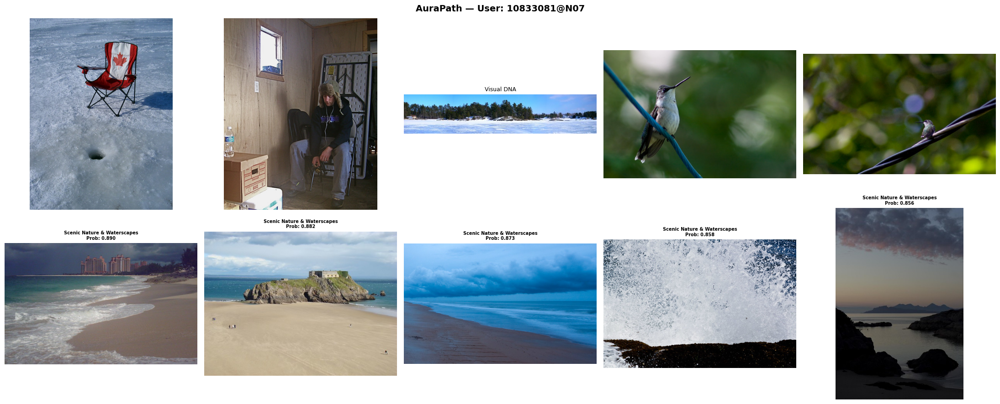


Top Recommendations:
  1. POI  66844 | Scenic Nature & Waterscapes         | Score: 0.8904
  2. POI  77300 | Scenic Nature & Waterscapes         | Score: 0.8820
  3. POI 104751 | Scenic Nature & Waterscapes         | Score: 0.8733
  4. POI  65229 | Scenic Nature & Waterscapes         | Score: 0.8578
  5. POI 142012 | Scenic Nature & Waterscapes         | Score: 0.8564


In [5]:
def demo_user(uid, top_k=5):
    print(f"\n{'='*60}")
    print(f"  AuraPath Recommendations for User: {uid}")
    print(f"{'='*60}")

    recs        = recommend_for_user(uid, top_k=top_k)
    user_images = get_user_images(uid, n=5)

    if not recs:
        print("No recommendations available.")
        return

    rec_images  = [get_poi_image(r['poi_id']) for r in recs]

    fig, axes   = plt.subplots(2, max(top_k, 5), figsize=(22, 9))
    fig.suptitle(f"AuraPath — User: {uid}", fontsize=14, fontweight='bold')

    # Row 1: User's Visual DNA
    for i in range(5):
        ax = axes[0, i]
        if i < len(user_images):
            ax.imshow(user_images[i])
        else:
            ax.set_facecolor('#eeeeee')
        ax.set_title("Visual DNA" if i == 2 else "", fontsize=9)
        ax.axis('off')

    # Row 2: Recommended POIs
    for i, rec in enumerate(recs):
        ax = axes[1, i]
        if rec_images[i] is not None:
            ax.imshow(rec_images[i])
        else:
            ax.set_facecolor('#dddddd')
            ax.text(0.5, 0.5, "No Image", ha='center',
                   va='center', transform=ax.transAxes)
        ax.set_title(
            f"{rec['cluster']}\nProb: {rec['score']:.3f}",
            fontsize=7, fontweight='bold'
        )
        ax.axis('off')

    axes[0, 0].set_ylabel("User Photos", fontsize=10, fontweight='bold')
    axes[1, 0].set_ylabel("Recommended", fontsize=10, fontweight='bold')

    plt.tight_layout()
    plt.show()

    print("\nTop Recommendations:")
    for i, r in enumerate(recs, 1):
        print(f"  {i}. POI {r['poi_id']:6d} | {r['cluster']:35s} | Score: {r['score']:.4f}")

# Demo — pick any user ID from your data
sample_uid = str(user_ids[np.random.randint(len(user_ids))])
demo_user(sample_uid, top_k=TOP_K)


  AuraPath Mood Recommendations: Live Events & Recreation


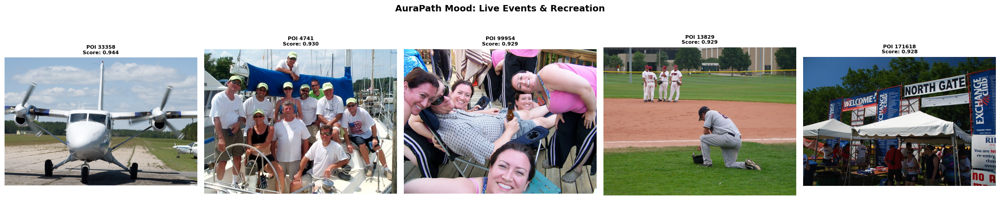


Top Mood-Based Recommendations:
  1. POI  33358 | Score: 0.9435
  2. POI   4741 | Score: 0.9298
  3. POI  99954 | Score: 0.9289
  4. POI  13829 | Score: 0.9288
  5. POI 171618 | Score: 0.9285

  AuraPath Mood Recommendations: Urban & Street Architecture


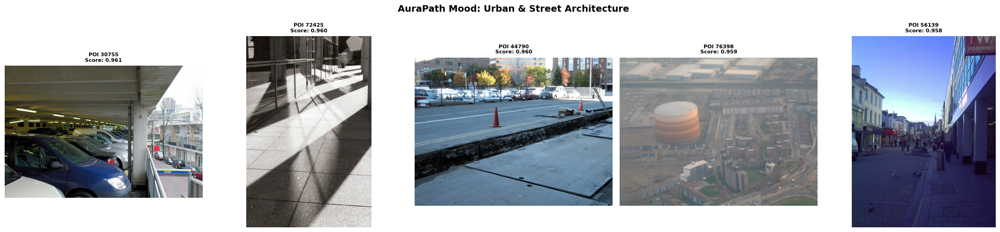


Top Mood-Based Recommendations:
  1. POI  30755 | Score: 0.9606
  2. POI  72425 | Score: 0.9597
  3. POI  44790 | Score: 0.9595
  4. POI  76398 | Score: 0.9585
  5. POI  56139 | Score: 0.9576

  AuraPath Mood Recommendations: Historic & Rural Heritage


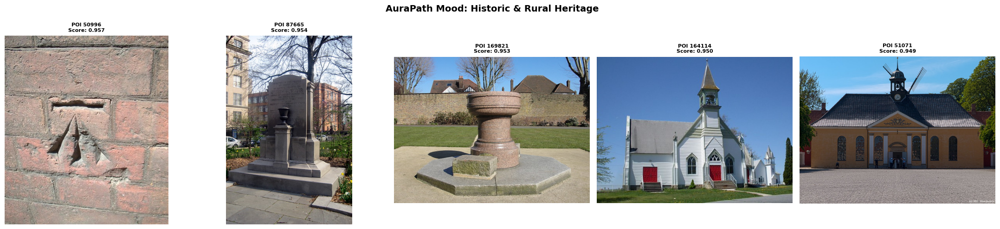


Top Mood-Based Recommendations:
  1. POI  50996 | Score: 0.9570
  2. POI  87665 | Score: 0.9536
  3. POI 169821 | Score: 0.9525
  4. POI 164114 | Score: 0.9495
  5. POI  51071 | Score: 0.9485

  AuraPath Mood Recommendations: Scenic Nature & Waterscapes


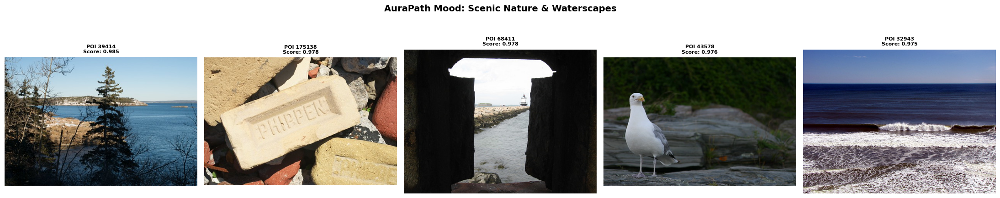


Top Mood-Based Recommendations:
  1. POI  39414 | Score: 0.9849
  2. POI 175138 | Score: 0.9781
  3. POI  68411 | Score: 0.9777
  4. POI  43578 | Score: 0.9764
  5. POI  32943 | Score: 0.9750

  AuraPath Mood Recommendations: Nightlife & Social Scenes


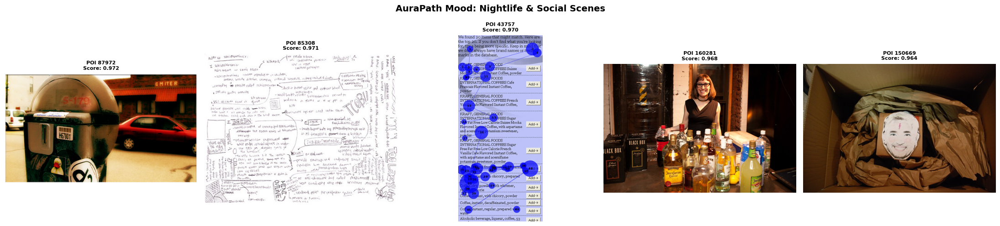


Top Mood-Based Recommendations:
  1. POI  87972 | Score: 0.9716
  2. POI  85308 | Score: 0.9711
  3. POI  43757 | Score: 0.9700
  4. POI 160281 | Score: 0.9676
  5. POI 150669 | Score: 0.9642

  AuraPath Mood Recommendations: Green Nature & Wildlife


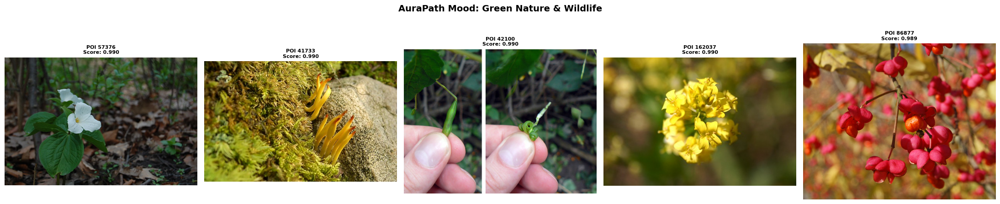


Top Mood-Based Recommendations:
  1. POI  57376 | Score: 0.9902
  2. POI  41733 | Score: 0.9899
  3. POI  42100 | Score: 0.9898
  4. POI 162037 | Score: 0.9897
  5. POI  86877 | Score: 0.9890


In [6]:
def demo_mood(mood_cluster_id, top_k=5):
    mood_name = CLUSTER_NAMES[mood_cluster_id]
    print(f"\n{'='*60}")
    print(f"  AuraPath Mood Recommendations: {mood_name}")
    print(f"{'='*60}")

    recs       = recommend_by_mood(mood_cluster_id, top_k=top_k)
    rec_images = [get_poi_image(r['poi_id']) for r in recs]

    fig, axes  = plt.subplots(1, top_k, figsize=(22, 5))
    fig.suptitle(
        f"AuraPath Mood: {mood_name}",
        fontsize=14, fontweight='bold'
    )

    for i, rec in enumerate(recs):
        ax = axes[i]
        if rec_images[i] is not None:
            ax.imshow(rec_images[i])
        else:
            ax.set_facecolor('#dddddd')
            ax.text(0.5, 0.5, "No Image", ha='center',
                   va='center', transform=ax.transAxes)
        ax.set_title(
            f"POI {rec['poi_id']}\nScore: {rec['score']:.3f}",
            fontsize=8, fontweight='bold'
        )
        ax.axis('off')

    plt.tight_layout()
    plt.show()

    print("\nTop Mood-Based Recommendations:")
    for i, r in enumerate(recs, 1):
        print(f"  {i}. POI {r['poi_id']:6d} | Score: {r['score']:.4f}")

# Demo all 6 moods
for cluster_id in range(6):
    demo_mood(cluster_id, top_k=TOP_K)

In [ ]:
# ============================================================
# CHANGE THESE VALUES TO TRY DIFFERENT USERS / MOODS
# ============================================================

MODE         = "user"    # "user" or "mood"
USER_ID      = "90366094@N00"   
MOOD_CLUSTER = 1                  # 0-5 (see CLUSTER_NAMES above)
TOP_K_DEMO   = 5

# ============================================================
print("CLUSTER NAMES:")
for k, v in CLUSTER_NAMES.items():
    print(f"  {k}: {v}")
print()

if MODE == "user":
    demo_user(USER_ID, top_k=TOP_K_DEMO)
elif MODE == "mood":
    demo_mood(MOOD_CLUSTER, top_k=TOP_K_DEMO)

CLUSTER NAMES:
  0: Live Events & Recreation
  1: Urban & Street Architecture
  2: Historic & Rural Heritage
  3: Scenic Nature & Waterscapes
  4: Nightlife & Social Scenes
  5: Green Nature & Wildlife


  AuraPath Recommendations for User: 90366094@N00


Random User ID: 90366094@N00
Found 9 images


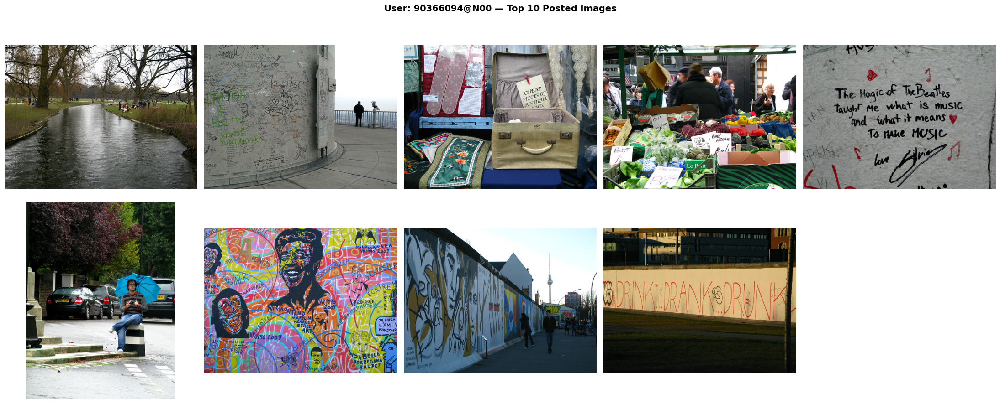


Copy this User ID to use in Cell 7: 90366094@N00


In [10]:
# Random user with top 10 posted images
random_uid = str(user_ids[np.random.randint(len(user_ids))])
print(f"Random User ID: {random_uid}")

images = get_user_images(random_uid, n=10)
print(f"Found {len(images)} images")

fig, axes = plt.subplots(2, 5, figsize=(22, 9))
fig.suptitle(f"User: {random_uid} — Top 10 Posted Images", fontsize=14, fontweight='bold')

for i, ax in enumerate(axes.flat):
    if i < len(images):
        ax.imshow(images[i])
    else:
        ax.set_facecolor('#eeeeee')
    ax.axis('off')

plt.tight_layout()
plt.show()

print(f"\nCopy this User ID to use in Cell 7: {random_uid}")